# Malawi extra inputs: construction and model-fit audit

This executed notebook reproduces the Zimbabwe-style audit for the Malawi 2022 and 2023 polygon cohorts. It validates the six Earth Engine exports, constructs model-ready monthly and static tables, and checks whether each source can vary inside a roughly 2 km village.

In [1]:
from pathlib import Path
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get('KENYA_MALAWI_EXTRA_INPUTS_ROOT', '../Google Earth/Kenya Malawi')).resolve()
DERIVED, REPORTS = ROOT / 'derived', ROOT / 'reports'
monthly = pd.read_parquet(DERIVED / 'malawi_model_ready_monthly_extra_inputs.parquet')
static = pd.read_parquet(DERIVED / 'malawi_model_ready_static_extra_inputs.parquet')
print(f'Monthly: {monthly.shape}; static: {static.shape}')

Monthly: (7101, 26); static: (789, 107)


## 1. Canonical structure

Every Malawi field contributes exactly nine October–June rows. The feature tables intentionally exclude the yield target; modelling joins labels later by `obs_id`.

In [2]:
cohort_summary = static.groupby('cohort', as_index=False).agg(fields=('obs_id','size'), median_area_ha=('field_area_ha','median'), median_elevation_m=('elevation','median'), median_slope_deg=('slope','median'))
cohort_summary

     cohort  fields  median_area_ha  median_elevation_m  median_slope_deg
malawi_2022     529         0.36869              1068.0          2.780288
malawi_2023     260         0.58570              1121.0          2.655975


## 2. Source completeness

    source  complete  expected time_scale  percent
Sentinel-1      7101      7101    monthly    100.0
 ERA5-Land      7101      7101    monthly    100.0
    CHIRPS      7101      7101    monthly    100.0
      SRTM       789       789     static    100.0
 SoilGrids       789       789     static    100.0
AlphaEarth       789       789     annual    100.0


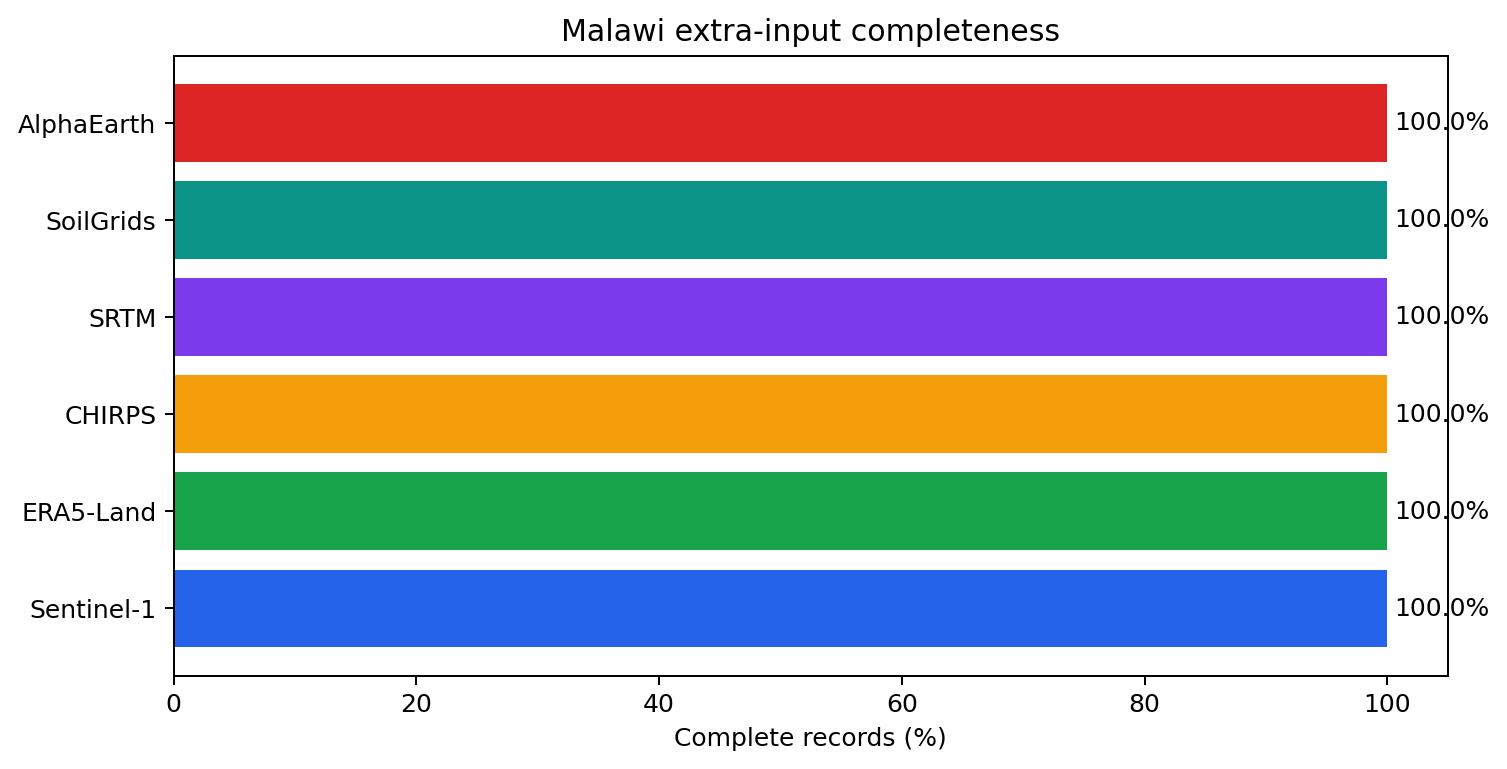

In [3]:
completeness = pd.DataFrame([['Sentinel-1', monthly.s1_available.sum(), len(monthly)], ['ERA5-Land', monthly.era5_available.sum(), len(monthly)], ['CHIRPS', monthly.chirps_available.sum(), len(monthly)], ['SRTM', static[['elevation','slope']].notna().all(axis=1).sum(), len(static)], ['SoilGrids', static.soilgrids_complete.sum(), len(static)], ['AlphaEarth', static.alphaearth_complete.sum(), len(static)]], columns=['source','complete','expected'])
completeness['percent'] = 100 * completeness.complete / completeness.expected
completeness

## 3. Sentinel-1 coverage and seasonal signal

Orbit direction is selected once per field using the direction with the most valid months. All 789 fields select descending, which is complete for all nine months.

s1_orbit
desc    789
Complete seasons: 789


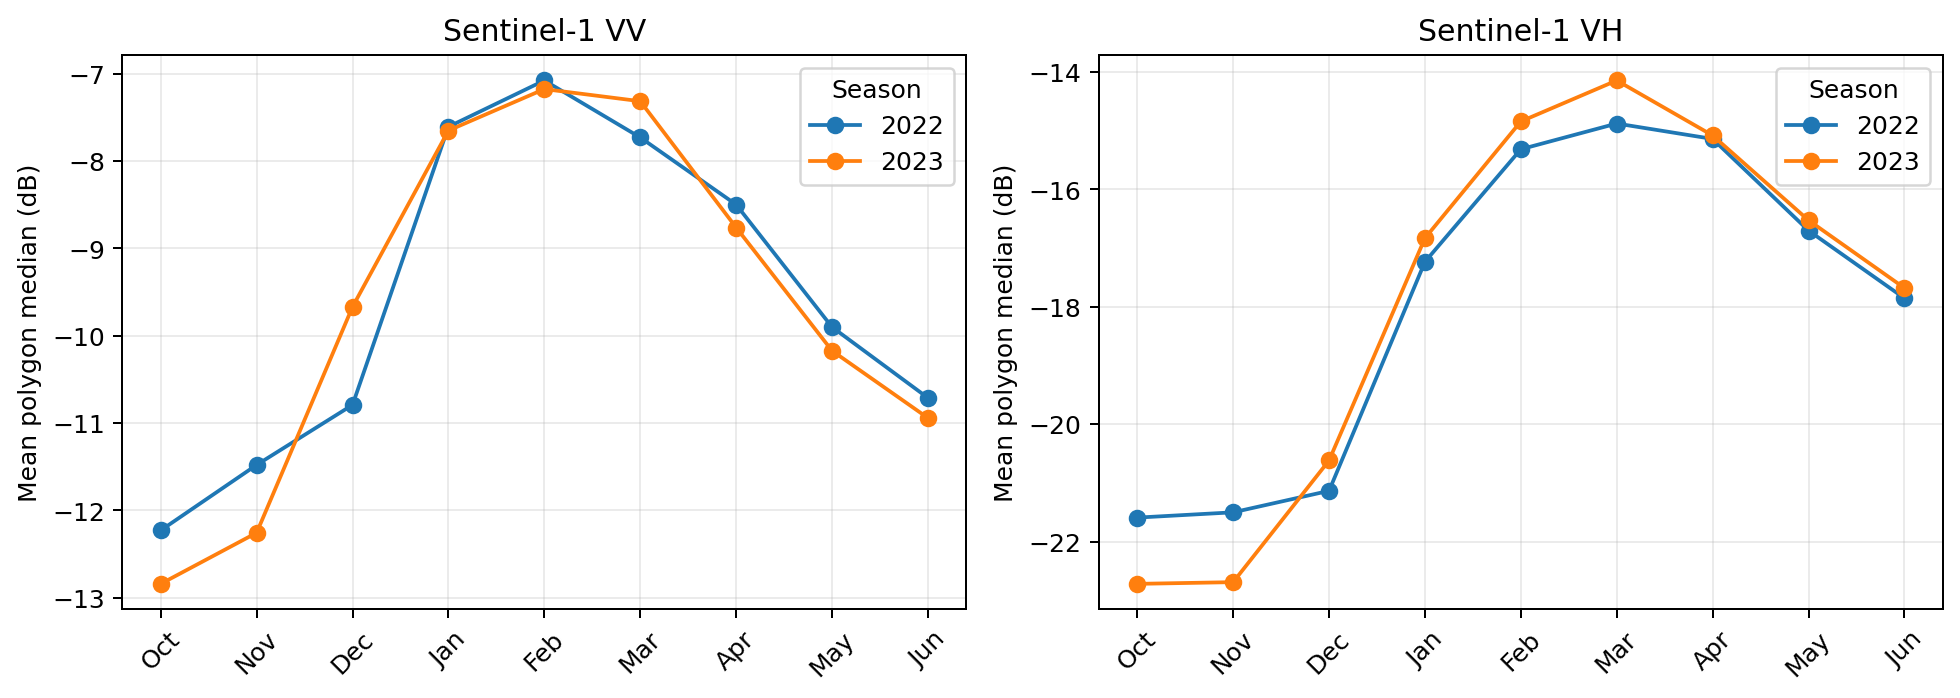

In [4]:
s1_observation = pd.read_csv(REPORTS / 'malawi_s1_observation_coverage.csv')
print(s1_observation.groupby('s1_orbit').size())
print('Complete seasons:', s1_observation.s1_complete_season.sum())

## 4. Weather consistency

ERA5-Land and CHIRPS are both complete. They agree strongly on monthly rainfall, but their 11 km and 5.5 km grids are contextual weather rather than field-resolving measurements.

CHIRPS–ERA5 rainfall correlation: 0.928


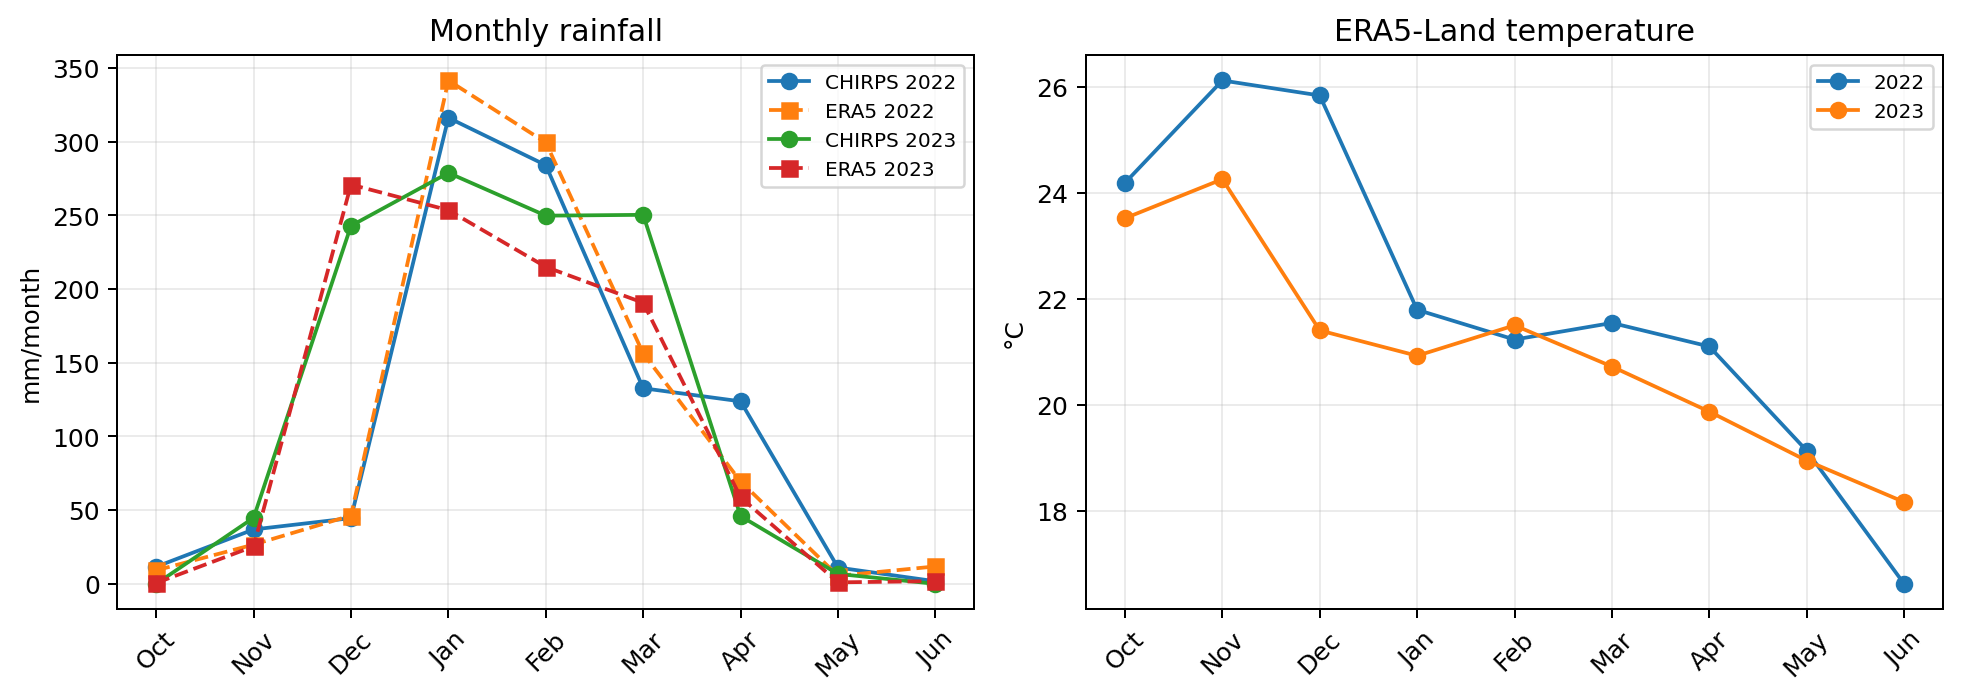

In [5]:
quality = json.loads((REPORTS / 'malawi_feature_quality_summary.json').read_text())
print('CHIRPS–ERA5 rainfall correlation:', round(quality['chirps_era5_precipitation_correlation'], 3))

## 5. Can sources distinguish fields inside a village?

The calculation uses 143 two-kilometre clusters containing multiple fields. High-resolution Sentinel-1, SRTM and AlphaEarth vary in almost every cluster. Coarse weather varies much less often, as expected.

                     source          resolution  multi_field_2km_clusters  clusters_with_more_than_one_value  share_varying_within_2km
Sentinel-1 VV seasonal mean 10 m polygon median                       143                                143                  1.000000
   CHIRPS seasonal rainfall             ~5.5 km                       143                                 34                  0.237762
ERA5-Land seasonal rainfall              ~11 km                       143                                 19                  0.132867
             SRTM elevation                30 m                       143                                142                  0.993007
        SoilGrids pH 0-5 cm               250 m                       143                                100                  0.699301
       SoilGrids SOC 0-5 cm               250 m                       143                                133                  0.930070
             AlphaEarth A00 10 m polygon median        

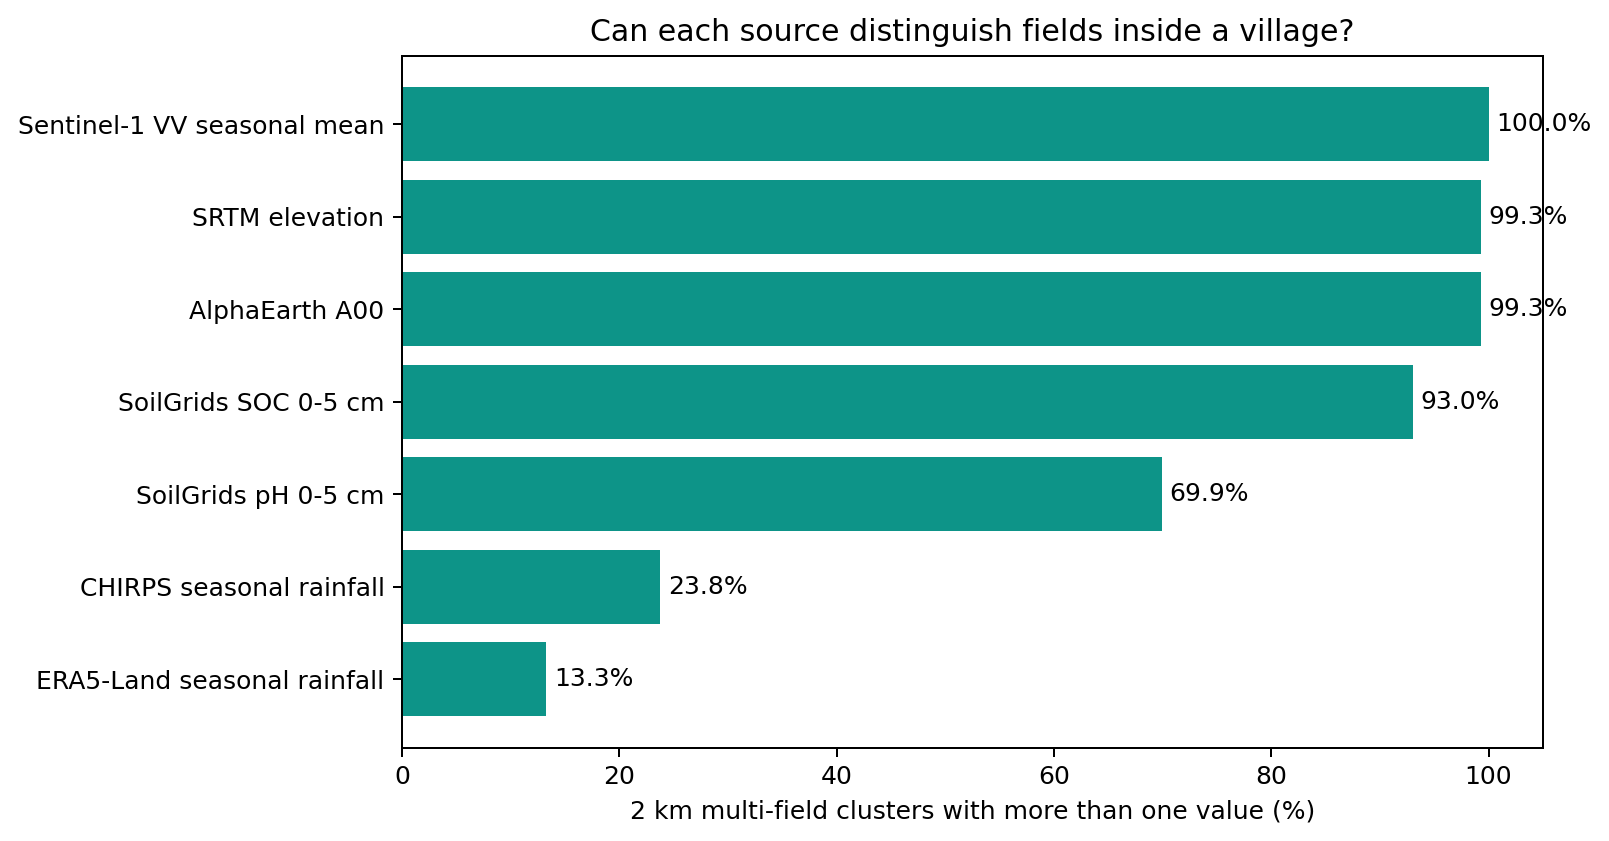

In [6]:
variation = pd.read_csv(REPORTS / 'malawi_within_village_variation.csv')
variation

## 6. AlphaEarth and Presto decisions

AlphaEarth is complete in all 64 dimensions and vector norms are close to one (median 0.9968). Repeated monthly exports of the same annual embedding differ by at most 1.67e-16, only floating-point roundoff; the static table uses their median.

AlphaEarth is **not** inserted into the monthly Presto channels. The annual season-year embedding can include observations after the June harvest and is therefore retained as a separate representation baseline. The Presto-compatible monthly table contains Sentinel-1 VV/VH, ERA5 temperature/rainfall, and SRTM elevation/slope. CHIRPS and SoilGrids are optional contextual additions.

In [7]:
status = pd.DataFrame([['Canonical keys','complete','7,101 unique field-month rows'], ['Sentinel-1','complete','7,101/7,101; descending orbit'], ['ERA5-Land','complete','7,101/7,101'], ['CHIRPS','complete','7,101/7,101'], ['SRTM','complete','789/789'], ['SoilGrids','complete','789/789'], ['AlphaEarth','complete with leakage warning','789/789; 64 dimensions'], ['Presto use','ready','VV, VH, temperature, rainfall, elevation and slope']], columns=['item','status','evidence'])
status

          item                        status                                           evidence
Canonical keys                      complete                      7,101 unique field-month rows
    Sentinel-1                      complete       7,101/7,101; descending orbit for all fields
     ERA5-Land                      complete                           7,101/7,101 monthly rows
        CHIRPS                      complete                           7,101/7,101 monthly rows
          SRTM                      complete                          789/789 polygon summaries
     SoilGrids                      complete                           789/789 centroid samples
    AlphaEarth complete with leakage warning                      789/789; 64 annual dimensions
    Presto use                         ready VV, VH, temperature, rainfall, elevation and slope


## Final conclusion

The Malawi extra-input extension is technically complete and can be joined to the frozen yield labels by `obs_id`. All required Presto channels are available without zero-filling. Sentinel-1, terrain and AlphaEarth can express field-to-field differences inside villages; ERA5 and CHIRPS should be interpreted as shared seasonal context. The remaining scientific test is whether these added inputs improve held-out-village and held-out-season yield prediction, not whether the data can be matched.